# Data analysis

Inspect saved datasets for coverage, quality, hourly patterns, seasonality, spatial differences, and distribution changes. No downloads or model training.

In [1]:
START_DATE = "2022-01-01"
END_DATE = "2026-10-18"
DATA_DIR = f"data/raw/{START_DATE}_{END_DATE}"
WEEK_START = "2024-06-01"
COMPARISON_MONTH = 6
EXPECTED_LOCATIONS = 10

In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().parent
DATA_PATH = ROOT / DATA_DIR
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True})

## Load saved files

Use the same directory as notebook 01. The files are read from disk, not from its kernel variables.

In [3]:
smard = pd.read_parquet(DATA_PATH / "smard.parquet")

In [4]:
weather = pd.read_parquet(DATA_PATH / "weather.parquet")

In [5]:
capacity = pd.read_parquet(DATA_PATH / "mastr.parquet")

In [6]:
calendar = pd.read_parquet(DATA_PATH / "calendar.parquet")

In [7]:
solar = pd.read_parquet(DATA_PATH / "solar.parquet")

In [8]:
datasets = {
    "SMARD": smard,
    "Weather": weather,
    "Capacity": capacity,
    "Calendar": calendar,
    "Solar": solar,
}
for frame in datasets.values():
    frame["timestamp_utc"] = pd.to_datetime(
        frame["timestamp_utc"], utc=True
    ).dt.as_unit("ns")

hours = pd.date_range(
    START_DATE,
    pd.Timestamp(END_DATE) + pd.Timedelta(days=1),
    freq="h",
    inclusive="left",
    tz="UTC",
).as_unit("ns")
weather_columns = (
    weather.select_dtypes(include="number")
    .columns.difference(["latitude", "longitude"])
    .tolist()
)

## 1. Time coverage and duplicate keys

Check the full UTC grid before comparing sources. Weather keys include location. SMARD preparation already removes duplicate timestamps, so this cannot audit duplicates removed upstream.

In [9]:
coverage = []
for name, frame in datasets.items():
    timestamps = pd.DatetimeIndex(frame.timestamp_utc.dropna().unique())
    keys = ["timestamp_utc", "location"] if name == "Weather" else ["timestamp_utc"]
    coverage.append(
        {
            "source": name,
            "rows": len(frame),
            "expected_rows": len(hours)
            * (EXPECTED_LOCATIONS if name == "Weather" else 1),
            "first_hour": timestamps.min(),
            "last_hour": timestamps.max(),
            "invalid_timestamps": int(frame.timestamp_utc.isna().sum()),
            "missing_hours": len(hours.difference(timestamps)),
            "outside_period": len(timestamps.difference(hours)),
            "duplicate_keys": int(frame.duplicated(keys).sum()),
        }
    )
display(pd.DataFrame(coverage).set_index("source"))

,rows,expected_rows,first_hour,last_hour,invalid_timestamps,missing_hours,outside_period,duplicate_keys
source,,,,,,,,
SMARD,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0,0,0,0
Weather,420480,420480,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0,0,0,0
Capacity,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0,0,0,0
Calendar,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0,0,0,0
Solar,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0,0,0,0


,rows,unique_hours,first_hour,last_hour,missing_hours
location,,,,,
Berlin,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Cologne,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Dortmund,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Frankfurt,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Hamburg,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Hannover,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Munich,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Nuremberg,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0
Potsdam,42048,42048,2022-01-01 00:00:00+00:00,2026-10-18 23:00:00+00:00,0


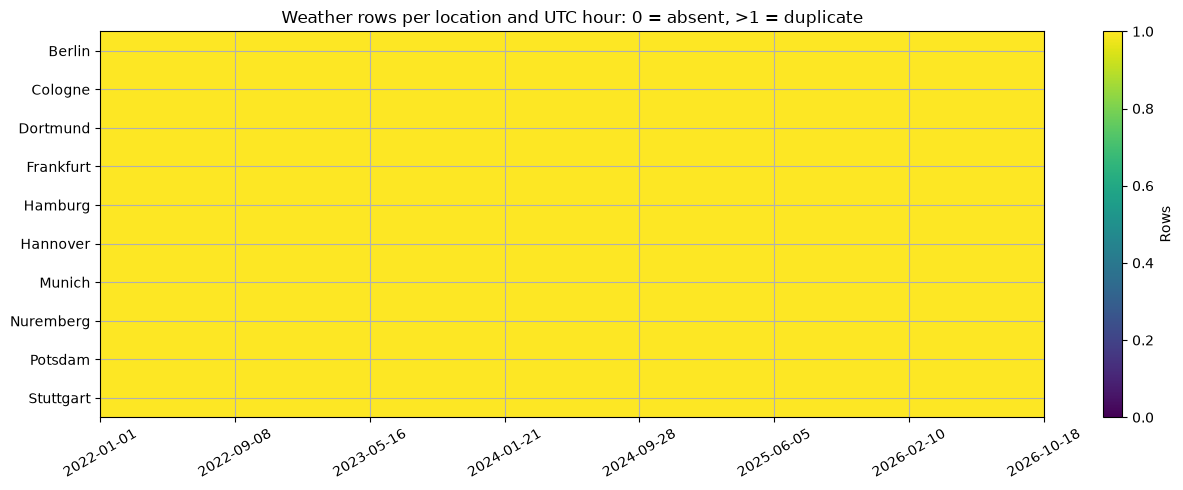

In [10]:
location_coverage = weather.groupby("location").agg(
    rows=("timestamp_utc", "size"),
    unique_hours=("timestamp_utc", "nunique"),
    first_hour=("timestamp_utc", "min"),
    last_hour=("timestamp_utc", "max"),
)
location_coverage["missing_hours"] = len(hours) - location_coverage.unique_hours
display(location_coverage)

presence = pd.crosstab(weather.timestamp_utc, weather.location).reindex(
    hours, fill_value=0
)
fig, ax = plt.subplots(figsize=(13, 5))
image = ax.imshow(presence.T, aspect="auto", interpolation="nearest", vmin=0)
ax.set_yticks(range(len(presence.columns)), presence.columns)
ticks = np.linspace(0, len(hours) - 1, min(8, len(hours)), dtype=int)
ax.set_xticks(ticks, hours[ticks].strftime("%Y-%m-%d"), rotation=30)
ax.set_title("Weather rows per location and UTC hour: 0 = absent, >1 = duplicate")
fig.colorbar(image, ax=ax, label="Rows")
plt.tight_layout()
plt.show()

## 2. Missing values and suspicious observations

Locate issues in time and inspect examples before deciding how to handle them. Zeros, missing records, and missing values are different cases.

In [11]:
quality = []
for name, frame in datasets.items():
    numeric = frame.select_dtypes(include="number")
    for column in numeric:
        values = numeric[column]
        quality.append(
            {
                "source": name,
                "column": column,
                "missing": int(values.isna().sum()),
                "missing_percent": 100 * values.isna().mean(),
                "zeros": int(values.eq(0).sum()),
                "negative": int(values.lt(0).sum()),
                "infinite": int(
                    np.isinf(values.to_numpy(dtype=float, na_value=np.nan)).sum()
                ),
            }
        )
display(pd.DataFrame(quality).set_index(["source", "column"]))

missing  missing_percent   zeros  \
source   column                                                          
SMARD    target_solar_generation_mwh        0              0.0     717   
         target_solar_generation_mw         0              0.0     717   
Weather  shortwave_radiation                0              0.0  194717   
         direct_radiation                   0              0.0  228390   
         diffuse_radiation                  0              0.0  194717   
         cloud_cover                        0              0.0   56547   
         cloud_cover_low                    0              0.0  163053   
         cloud_cover_mid                    0              0.0  164856   
         cloud_cover_high                   0              0.0  195960   
         temperature_2m                     0              0.0     876   
         precipitation                      0              0.0  358422   
         wind_speed_10m                     0              0.0     131   
         latitude                           0              0.0       0   
         longitude                          0              0.0       0   
Capacity installed_pv_capacity_mw           0              0.0       0   
Calendar hour_local                         0              0.0    1752   
         day_of_year                        0              0.0       0   
         month                              0              0.0       0   
         weekday                            0              0.0    6002   
         is_weekend                         0              0.0   30002   
         is_holiday_de                      0              0.0   41017   
         hour_sin                           0              0.0    1752   
         hour_cos                           0              0.0       0   
         day_of_year_sin                    0              0.0       0   
         day_of_year_cos                    0              0.0       0   
Solar    solar_elevation_mean               0              0.0       0   
         solar_apparent_zenith_mean         0              0.0       0   
         clear_sky_ghi_mean                 0              0.0   19585   
         clear_sky_dni_mean                 0              0.0   19585   
         clear_sky_dhi_mean                 0              0.0   19585   
         solar_elevation_max                0              0.0       0   
         clear_sky_ghi_max                  0              0.0   19585   
         is_daylight_anywhere               0              0.0   19811   

                                      negative  infinite  
source   column                                           
SMARD    target_solar_generation_mwh         0         0  
         target_solar_generation_mw          0         0  
Weather  shortwave_radiation                 0         0  
         direct_radiation                    0         0  
         diffuse_radiation                   0         0  
         cloud_cover                         0         0  
         cloud_cover_low                     0         0  
         cloud_cover_mid                     0         0  
         cloud_cover_high                    0         0  
         temperature_2m                  25413         0  
         precipitation                       0         0  
         wind_speed_10m                      0         0  
         latitude                            0         0  
         longitude                           0         0  
Capacity installed_pv_capacity_mw            0         0  
Calendar hour_local                          0         0  
         day_of_year                         0         0  
         month                               0         0  
         weekday                             0         0  
         is_weekend                          0         0  
         is_holiday_de                       0         0  
         hour_sin                        19272         0  
         hour_cos              

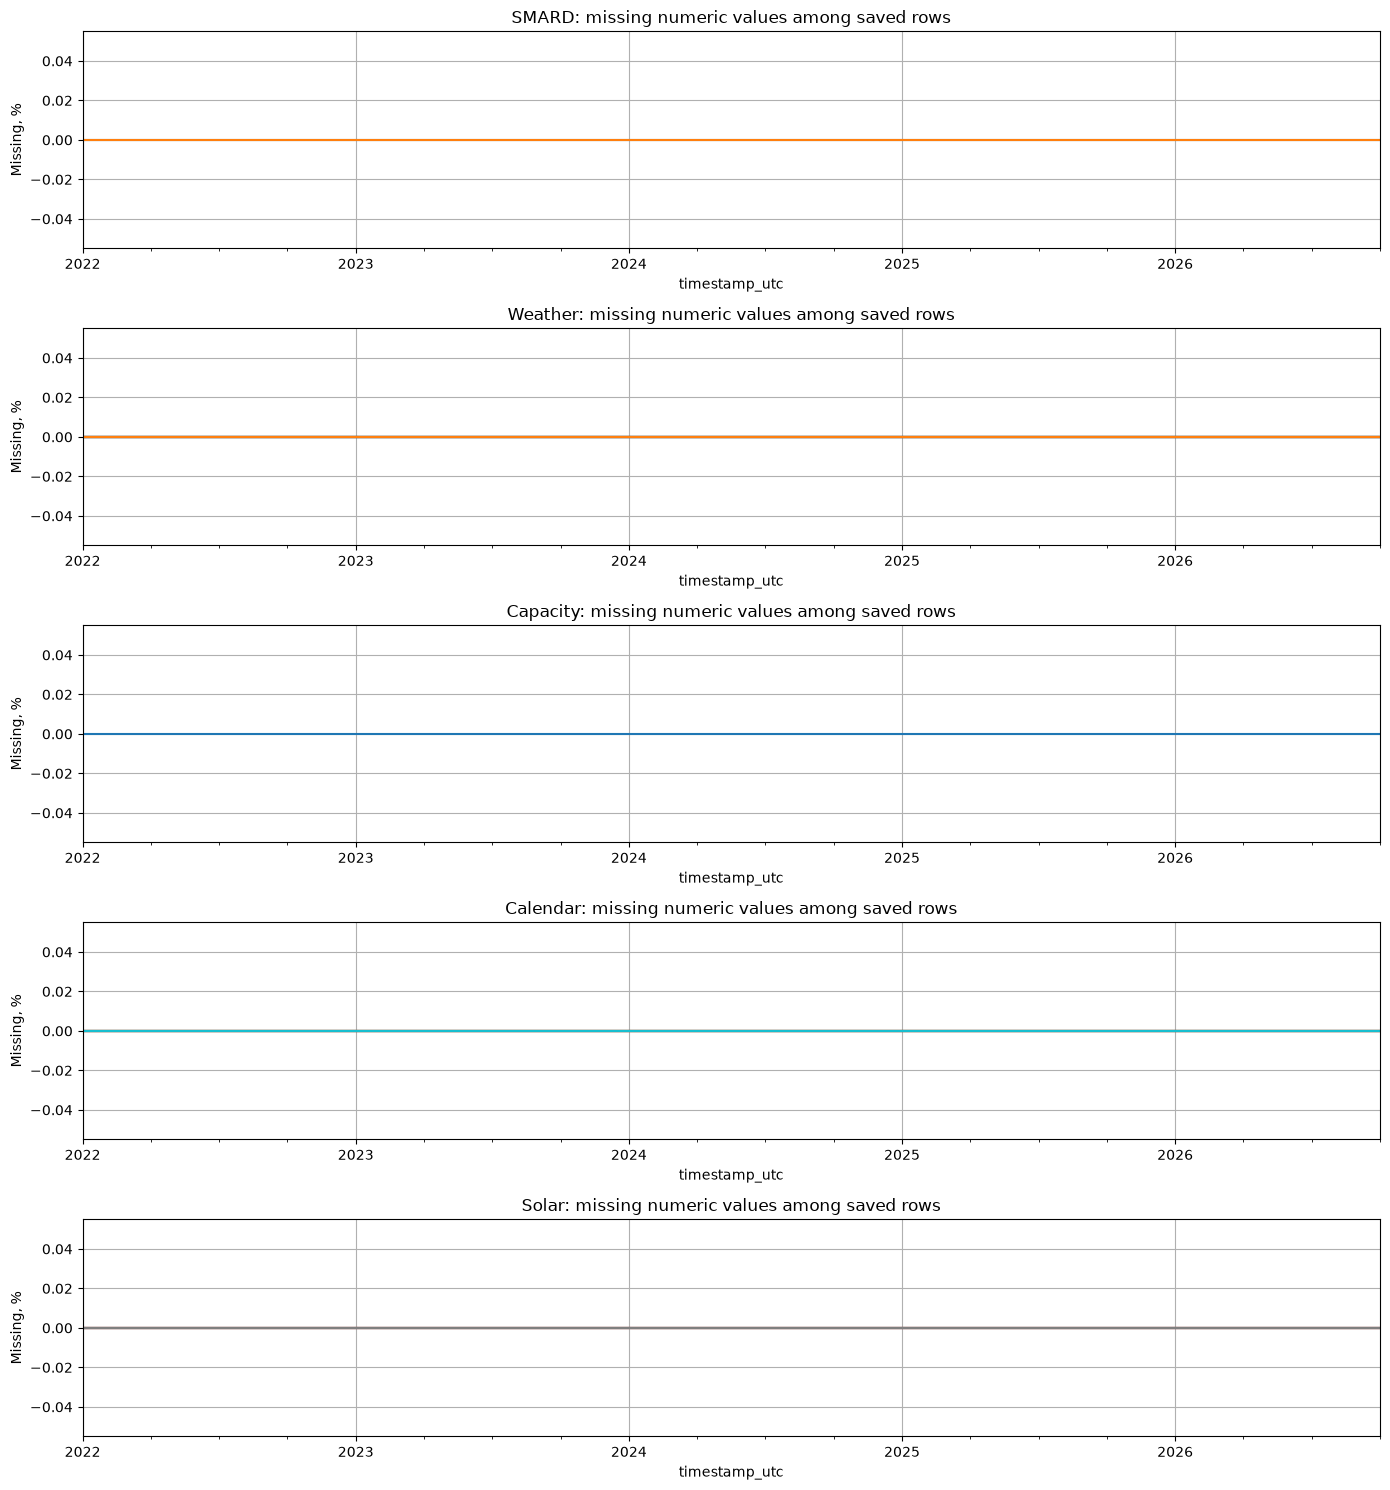

In [12]:
fig, axes = plt.subplots(len(datasets), 1, figsize=(14, 15))
for ax, (name, frame) in zip(axes, datasets.items(), strict=True):
    numeric_columns = frame.select_dtypes(include="number").columns
    missing = (
        frame.set_index("timestamp_utc")[numeric_columns].isna().resample("MS").mean()
        * 100
    )
    missing.plot(ax=ax, legend=False)
    ax.set_title(f"{name}: missing numeric values among saved rows")
    ax.set_ylabel("Missing, %")
plt.tight_layout()
plt.show()

In [13]:
cloud_columns = [
    column for column in weather_columns if column.startswith("cloud_cover")
]
cloud_invalid = (weather[cloud_columns].lt(0) | weather[cloud_columns].gt(100)).any(
    axis=1
)
radiation_columns = ["shortwave_radiation", "direct_radiation", "diffuse_radiation"]
radiation_invalid = weather[radiation_columns].lt(0).any(axis=1)

display(
    pd.Series(
        {
            "negative_generation": int(smard.target_solar_generation_mw.lt(0).sum()),
            "cloud_cover_outside_0_100": int(cloud_invalid.sum()),
            "negative_radiation": int(radiation_invalid.sum()),
            "nonpositive_capacity": int(capacity.installed_pv_capacity_mw.le(0).sum()),
        },
        name="flagged_rows",
    )
)
display(weather.loc[cloud_invalid | radiation_invalid].head(20))

negative_generation          0
cloud_cover_outside_0_100    0
negative_radiation           0
nonpositive_capacity         0
Name: flagged_rows, dtype: int64

,shortwave_radiation,direct_radiation,diffuse_radiation,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,temperature_2m,precipitation,wind_speed_10m,timestamp_utc,location,latitude,longitude


## 3. Hourly generation and solar patterns

Compare generation, weather, and solar features on their shared UTC timestamps. Sources are joined without temporal shifts, consistently with training and inference.

In [14]:
weather_grouped = weather.groupby("timestamp_utc")[weather_columns]
weather_mean = weather_grouped.mean().where(
    weather_grouped.count().eq(EXPECTED_LOCATIONS)
)
weather_mean = weather_mean.add_prefix("weather_").reset_index()

hourly = smard.merge(capacity, on="timestamp_utc", how="outer", validate="one_to_one")
hourly = hourly.merge(solar, on="timestamp_utc", how="outer", validate="one_to_one")
hourly = hourly.merge(
    weather_mean, on="timestamp_utc", how="outer", validate="one_to_one"
)
hourly = (
    hourly.set_index("timestamp_utc")
    .reindex(hours)
    .rename_axis("timestamp_utc")
    .reset_index()
)

hourly["capacity_factor"] = (
    hourly.target_solar_generation_mw
    / hourly.installed_pv_capacity_mw.where(hourly.installed_pv_capacity_mw > 0)
)
local_time = hourly.timestamp_utc.dt.tz_convert("Europe/Berlin")
hourly["hour_local"] = local_time.dt.hour
hourly["month_utc"] = hourly.timestamp_utc.dt.month
hourly["year_utc"] = hourly.timestamp_utc.dt.year

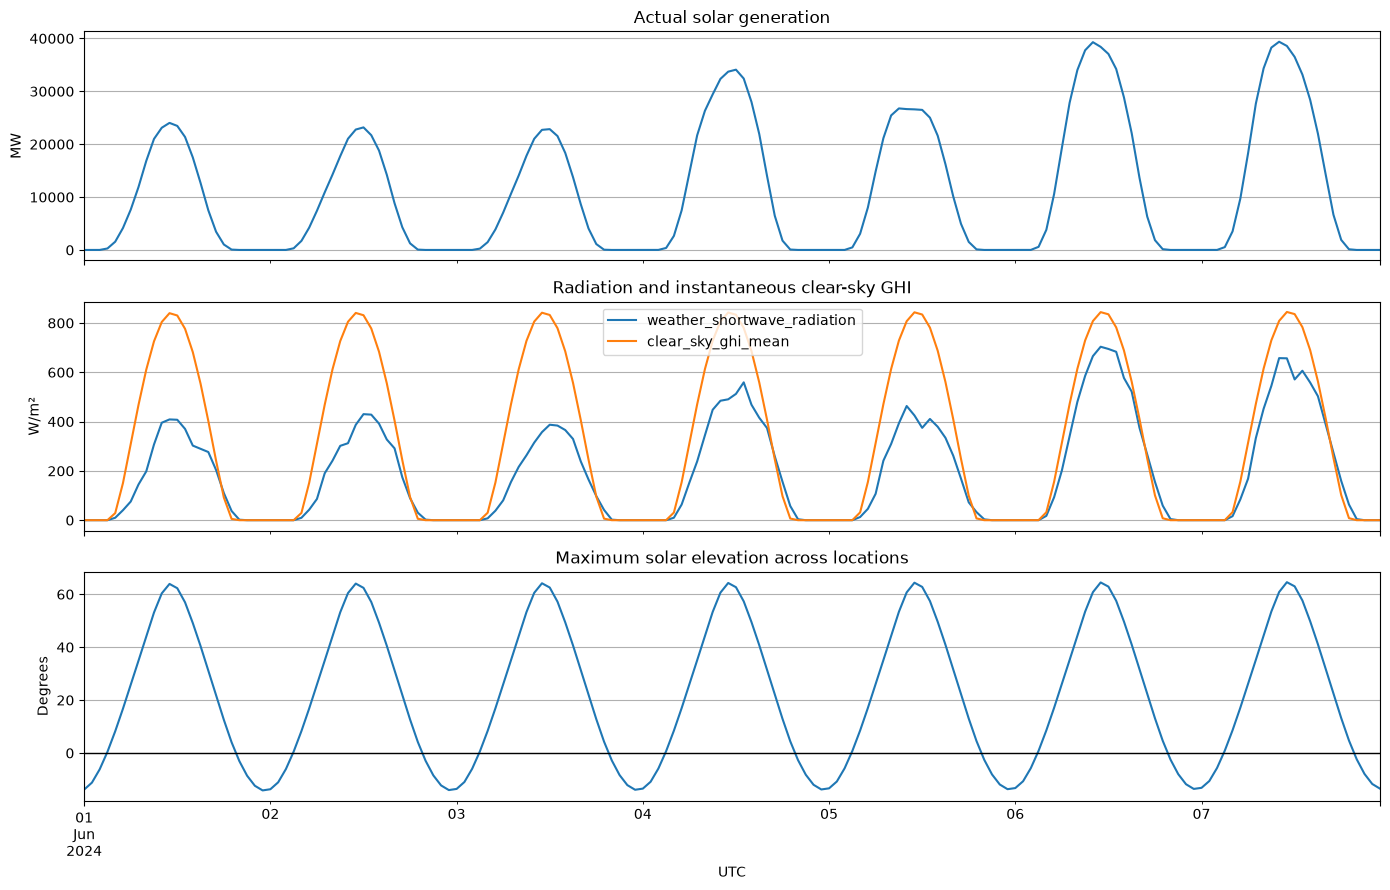

In [15]:
week_start = pd.Timestamp(WEEK_START, tz="UTC")
week = hourly.loc[
    hourly.timestamp_utc.ge(week_start)
    & hourly.timestamp_utc.lt(week_start + pd.Timedelta(days=7))
].set_index("timestamp_utc")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
week.target_solar_generation_mw.plot(ax=axes[0], title="Actual solar generation")
axes[0].set_ylabel("MW")
week[["weather_shortwave_radiation", "clear_sky_ghi_mean"]].plot(
    ax=axes[1], title="Radiation and instantaneous clear-sky GHI"
)
axes[1].set_ylabel("W/m²")
week.solar_elevation_max.plot(
    ax=axes[2], title="Maximum solar elevation across locations"
)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_ylabel("Degrees")
axes[2].set_xlabel("UTC")
plt.tight_layout()
plt.show()

In [16]:
night = hourly.solar_elevation_max.notna() & hourly.solar_elevation_max.le(0)
night_generation = hourly.loc[night & hourly.target_solar_generation_mw.gt(0)]
print(
    "Energy share in hours classified as night, %:",
    100
    * hourly.loc[night, "target_solar_generation_mwh"].sum()
    / hourly.target_solar_generation_mwh.sum(),
)
display(
    night_generation.nlargest(20, "target_solar_generation_mw")[
        [
            "timestamp_utc",
            "target_solar_generation_mw",
            "weather_shortwave_radiation",
            "solar_elevation_max",
        ]
    ]
)

calendar_alignment = calendar.merge(
    hourly[["timestamp_utc", "hour_local"]],
    on="timestamp_utc",
    suffixes=("_saved", "_expected"),
    validate="one_to_one",
)
print(
    "Calendar local-hour mismatches:",
    int(
        calendar_alignment.hour_local_saved.ne(
            calendar_alignment.hour_local_expected
        ).sum()
    ),
)

Energy share in hours classified as night, %: 0.14590310821342875


,timestamp_utc,target_solar_generation_mw,weather_shortwave_radiation,solar_elevation_max
36462,2026-02-28 06:00:00+00:00,2052.83,0.0,-0.130435
33582,2025-10-31 06:00:00+00:00,1761.51,0.0,-0.455263
35551,2026-01-21 07:00:00+00:00,1745.19,0.0,-0.020959
36438,2026-02-27 06:00:00+00:00,1719.97,0.0,-0.459326
35527,2026-01-20 07:00:00+00:00,1716.96,0.0,-0.154050
41501,2026-09-26 05:00:00+00:00,1571.21,0.0,-0.655754
33606,2025-11-01 06:00:00+00:00,1478.91,0.0,-0.696122
41477,2026-09-25 05:00:00+00:00,1473.05,0.0,-0.399558
41525,2026-09-27 05:00:00+00:00,1392.78,0.0,-0.912341
35503,2026-01-19 07:00:00+00:00,1375.98,0.0,-0.280505


Calendar local-hour mismatches: 0


## 4. Spatial weather coverage

Inspect individual locations before averaging. These plots show sampling geometry and weather differences; they do not establish PV-capacity-weighted coverage.

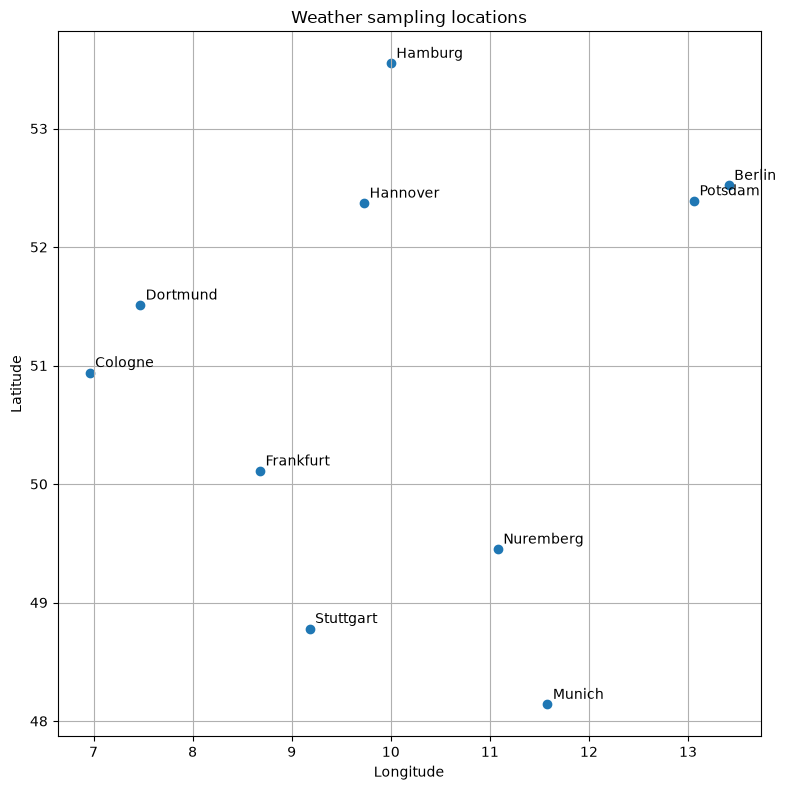

In [17]:
locations = weather[["location", "latitude", "longitude"]].drop_duplicates()
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(locations.longitude, locations.latitude)
for point in locations.itertuples(index=False):
    ax.annotate(
        str(point.location),
        (point.longitude, point.latitude),
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Weather sampling locations")
plt.tight_layout()
plt.show()

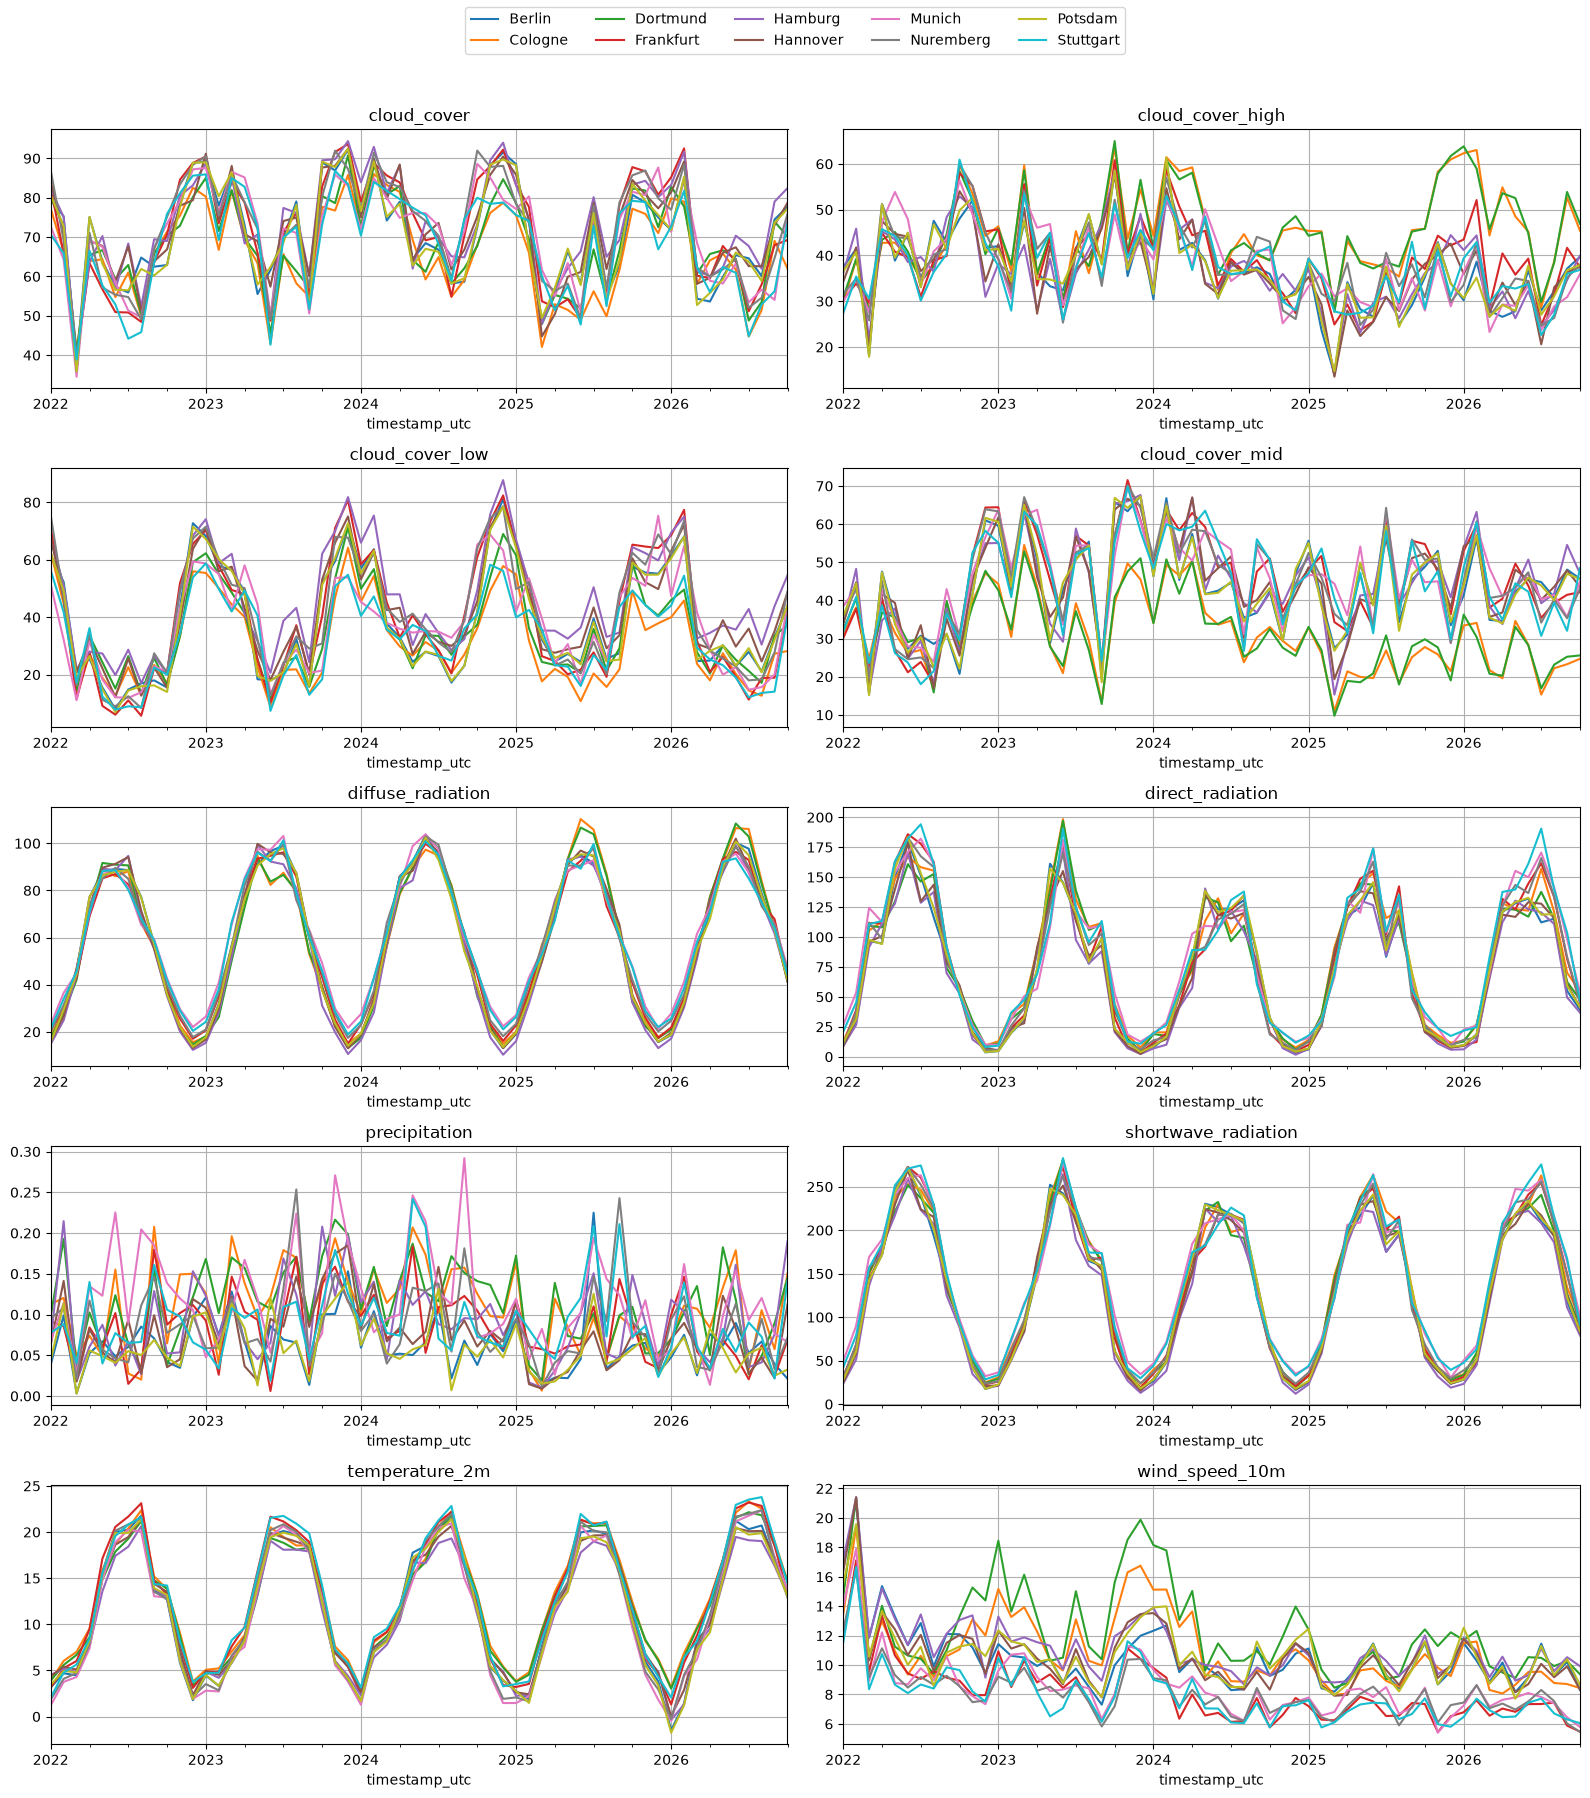

In [18]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18))
for ax, column in zip(axes.flat, weather_columns, strict=True):
    monthly = (
        weather.pivot(index="timestamp_utc", columns="location", values=column)
        .resample("MS")
        .mean()
    )
    monthly.plot(ax=ax, legend=False, title=column)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="upper center")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 5. Daily and annual structure

Sum hourly energy and average power. Daily energy is shown only for complete 24-hour UTC days; seasonality is inspected at several time scales.

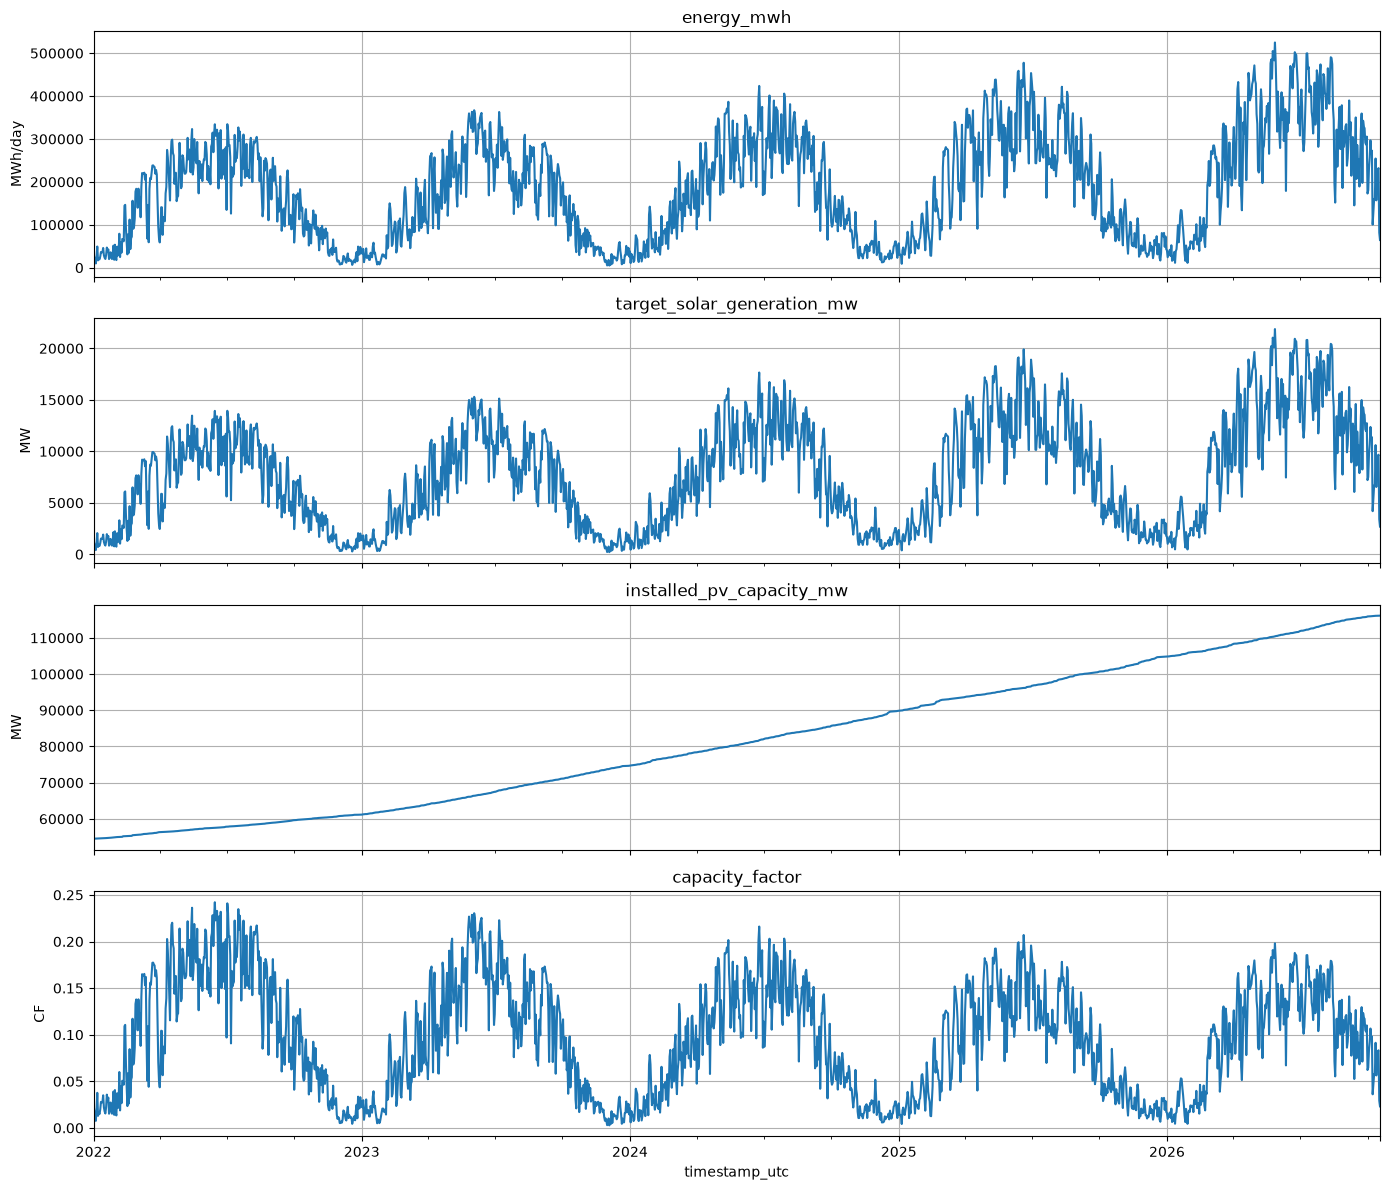

In [19]:
indexed = hourly.set_index("timestamp_utc")
daily = (
    indexed[
        ["target_solar_generation_mw", "capacity_factor", "installed_pv_capacity_mw"]
    ]
    .resample("D")
    .mean()
)
daily["energy_mwh"] = indexed.target_solar_generation_mwh.resample("D").sum(
    min_count=24
)

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, column, unit in zip(
    axes,
    [
        "energy_mwh",
        "target_solar_generation_mw",
        "installed_pv_capacity_mw",
        "capacity_factor",
    ],
    ["MWh/day", "MW", "MW", "CF"],
    strict=True,
):
    daily[column].plot(ax=ax, title=column)
    ax.set_ylabel(unit)
plt.tight_layout()
plt.show()

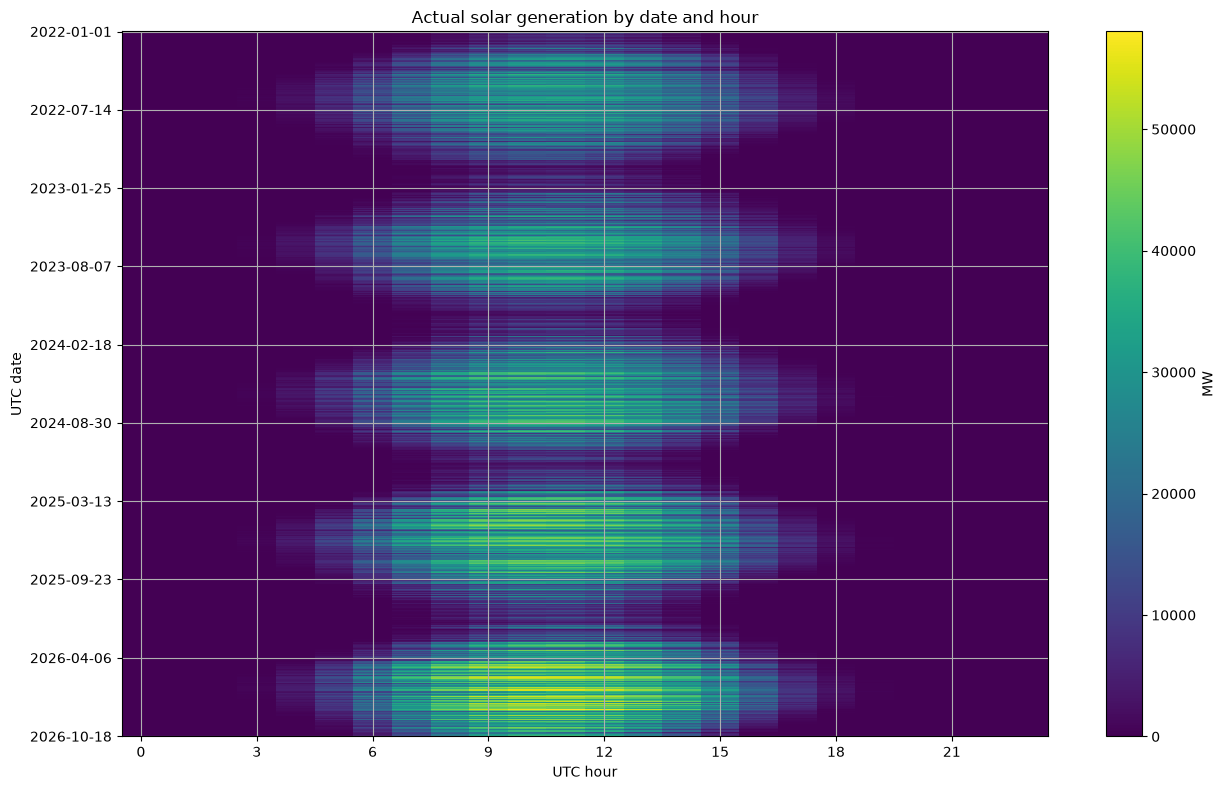

In [20]:
generation_map = hourly.assign(
    date_utc=hourly.timestamp_utc.dt.date, hour_utc=hourly.timestamp_utc.dt.hour
)
generation_map = generation_map.pivot(
    index="date_utc", columns="hour_utc", values="target_solar_generation_mw"
)
fig, ax = plt.subplots(figsize=(13, 8))
image = ax.imshow(
    generation_map, aspect="auto", interpolation="nearest", cmap="viridis"
)
ticks = np.linspace(0, len(generation_map) - 1, min(10, len(generation_map)), dtype=int)
ax.set_yticks(ticks, generation_map.index[ticks].astype(str))
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("UTC hour")
ax.set_ylabel("UTC date")
ax.set_title("Actual solar generation by date and hour")
fig.colorbar(image, ax=ax, label="MW")
plt.tight_layout()
plt.show()

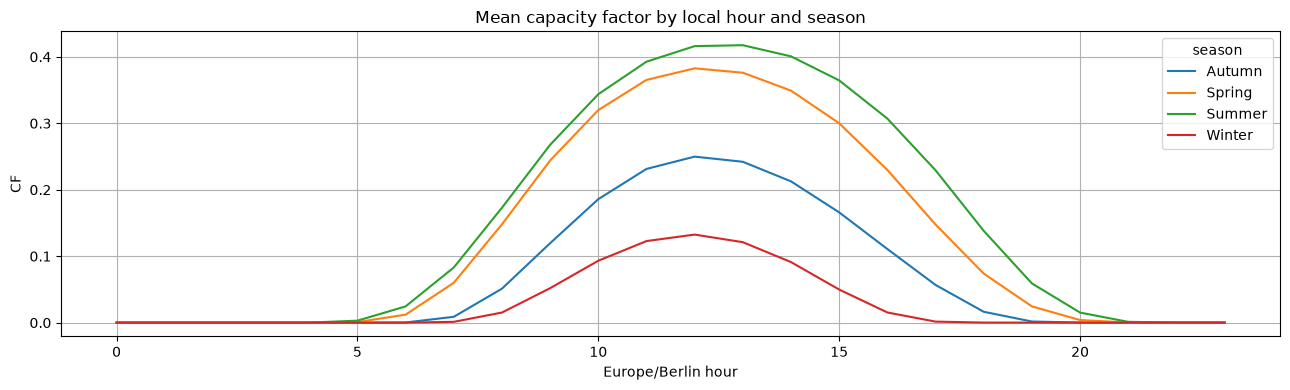

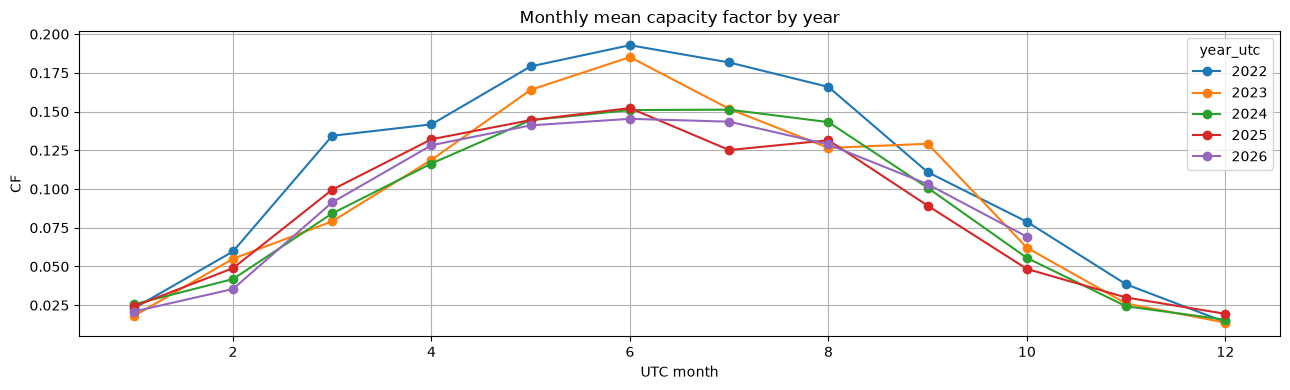

In [21]:
season_names = {
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn",
    12: "Winter",
}
hourly["season"] = local_time.dt.month.map(season_names)
profiles = hourly.pivot_table(
    index="hour_local", columns="season", values="capacity_factor", aggfunc="mean"
)
profiles.plot(title="Mean capacity factor by local hour and season")
plt.xlabel("Europe/Berlin hour")
plt.ylabel("CF")
plt.tight_layout()
plt.show()

monthly_cf = hourly.pivot_table(
    index="month_utc", columns="year_utc", values="capacity_factor", aggfunc="mean"
)
monthly_cf.plot(marker="o", title="Monthly mean capacity factor by year")
plt.xlabel("UTC month")
plt.ylabel("CF")
plt.tight_layout()
plt.show()

## 6. Capacity reconstruction and normalization

Check the denominator before interpreting capacity factor. MaStR uses an operating-fleet snapshot; arithmetic checks cannot establish point-in-time historical accuracy.

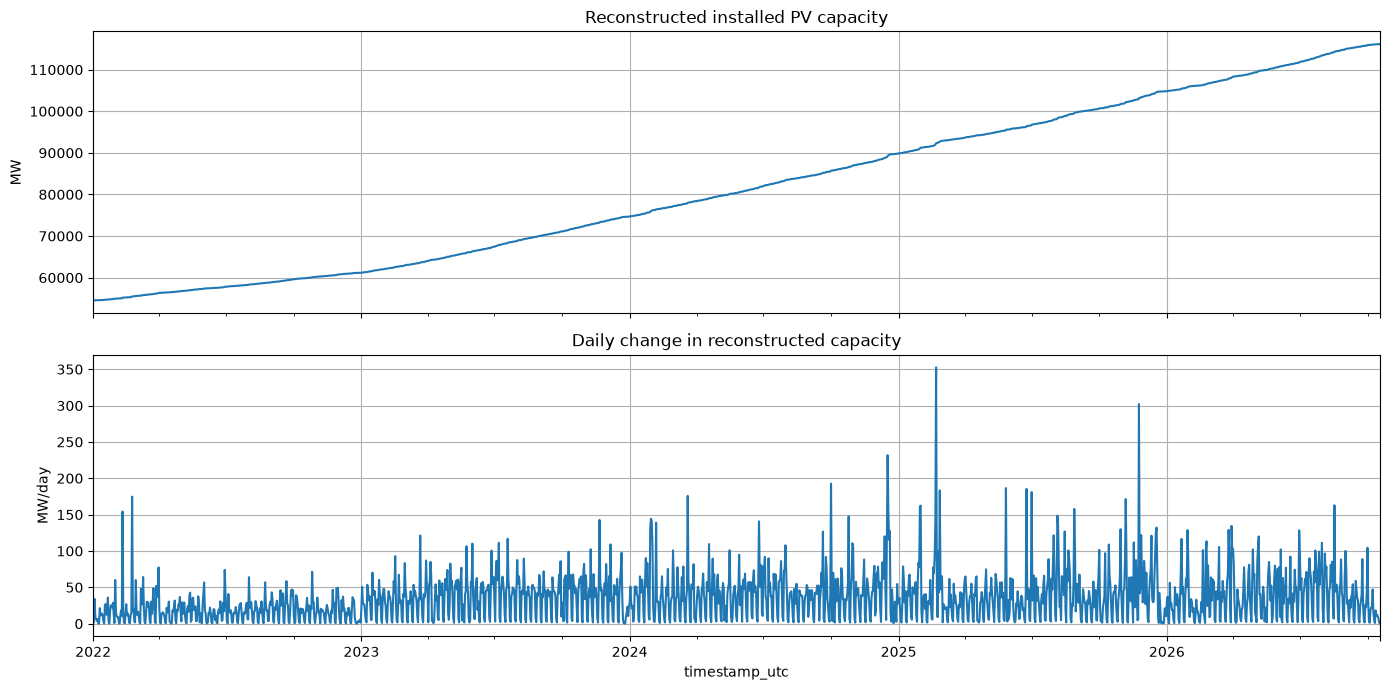

,absolute_change_mw
timestamp_utc,
2025-02-21 00:00:00+00:00,352.632607
2025-11-24 00:00:00+00:00,302.197523
2024-12-17 00:00:00+00:00,231.798594
2024-10-01 00:00:00+00:00,192.544818
2025-05-27 00:00:00+00:00,186.497587
2025-06-24 00:00:00+00:00,185.427809
2025-02-26 00:00:00+00:00,183.293017
2025-07-01 00:00:00+00:00,181.053784
2024-03-20 00:00:00+00:00,175.791474


,timestamp_utc,target_solar_generation_mw,installed_pv_capacity_mw,capacity_factor


In [22]:
capacity_daily = (
    capacity.set_index("timestamp_utc").installed_pv_capacity_mw.resample("D").first()
)
capacity_change = capacity_daily.diff()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
capacity_daily.plot(ax=axes[0], title="Reconstructed installed PV capacity")
axes[0].set_ylabel("MW")
capacity_change.plot(ax=axes[1], title="Daily change in reconstructed capacity")
axes[1].set_ylabel("MW/day")
plt.tight_layout()
plt.show()

display(capacity_change.abs().nlargest(15).to_frame("absolute_change_mw"))
display(
    hourly.loc[
        hourly.capacity_factor.lt(0) | hourly.capacity_factor.gt(1),
        [
            "timestamp_utc",
            "target_solar_generation_mw",
            "installed_pv_capacity_mw",
            "capacity_factor",
        ],
    ].head(20)
)

## 7. Relationships and distribution changes

Inspect daylight separately to avoid correlations driven by shared night-time zeros. Compare matching seasons; a partial final year and weather differences do not establish concept drift.

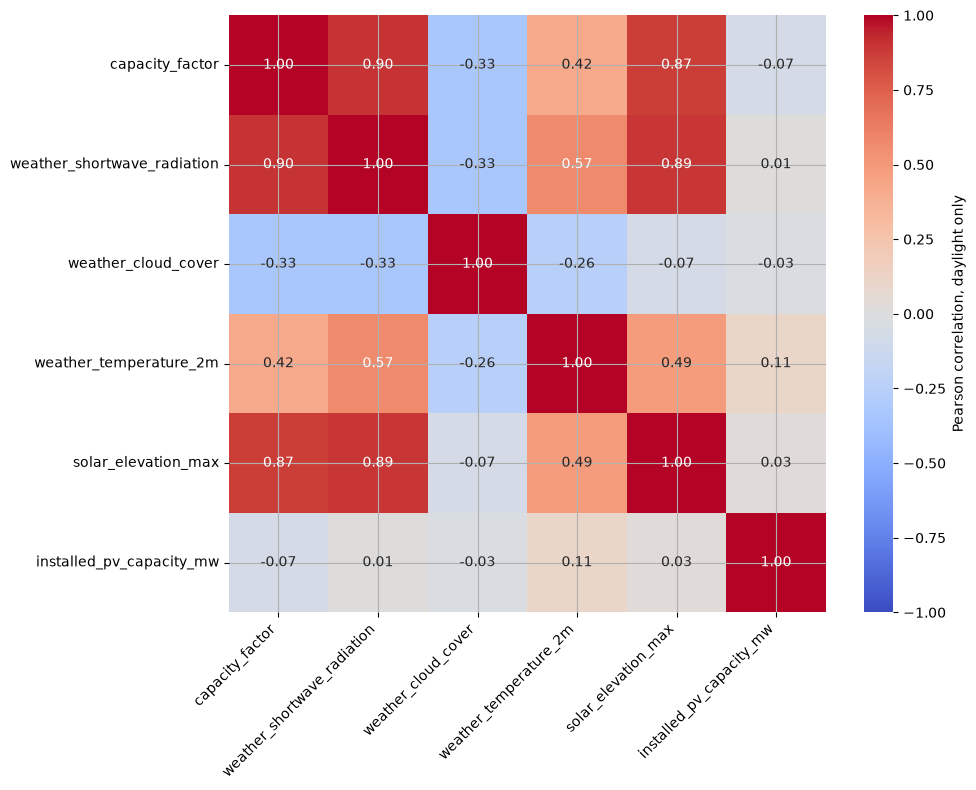

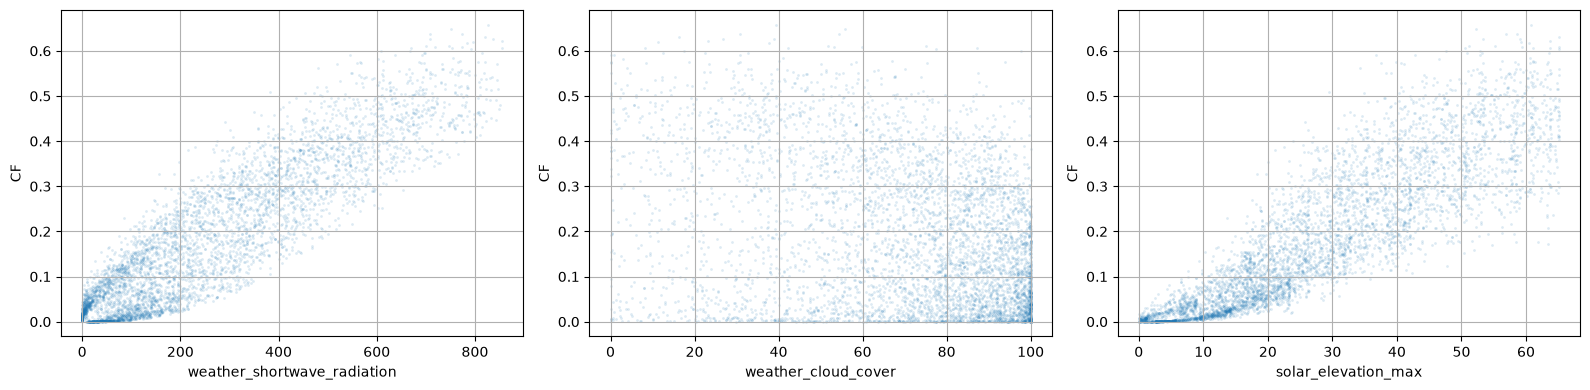

In [27]:
daylight = hourly.loc[hourly.solar_elevation_max.gt(0)].copy()
columns = [
    "capacity_factor",
    "weather_shortwave_radiation",
    "weather_cloud_cover",
    "weather_temperature_2m",
    "solar_elevation_max",
    "installed_pv_capacity_mw",
]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    daylight[columns].corr(),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="coolwarm",
    square=True,
    cbar_kws={"label": "Pearson correlation, daylight only"},
    ax=ax,
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

sample = daylight.sample(n=min(5000, len(daylight)), random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(
    axes,
    ["weather_shortwave_radiation", "weather_cloud_cover", "solar_elevation_max"],
    strict=True,
):
    sns.scatterplot(
        data=sample,
        x=column,
        y="capacity_factor",
        s=4,
        alpha=0.15,
        linewidth=0,
        ax=ax,
    )
    ax.set_ylabel("CF")
plt.tight_layout()
plt.show()

In [24]:
annual = hourly.groupby("year_utc").agg(
    rows=("timestamp_utc", "size"),
    valid_generation_hours=("target_solar_generation_mw", "count"),
    mean_generation_mw=("target_solar_generation_mw", "mean"),
    mean_cf=("capacity_factor", "mean"),
    std_cf=("capacity_factor", "std"),
    mean_radiation=("weather_shortwave_radiation", "mean"),
    mean_cloud_cover=("weather_cloud_cover", "mean"),
)
display(annual)

hourly["period"] = hourly.timestamp_utc.dt.tz_localize(None).dt.to_period("M")
month_counts = hourly.groupby("period").capacity_factor.count().to_frame("valid_hours")
month_counts["expected_hours"] = pd.PeriodIndex(month_counts.index).days_in_month * 24
complete_periods = month_counts.index[
    month_counts.valid_hours.eq(month_counts.expected_hours)
]
matched = hourly.loc[hourly.period.isin(complete_periods)]
month_years = matched.groupby("month_utc").year_utc.nunique()
common_months = month_years.index[month_years.eq(hourly.year_utc.nunique())]
print("Complete calendar months present in every year:", common_months.tolist())
display(
    matched.loc[matched.month_utc.isin(common_months)]
    .groupby("year_utc")
    .agg(
        hours=("capacity_factor", "count"),
        mean_cf=("capacity_factor", "mean"),
        std_cf=("capacity_factor", "std"),
    )
)

,rows,valid_generation_hours,mean_generation_mw,mean_cf,std_cf,mean_radiation,mean_cloud_cover
year_utc,,,,,,,
2022,8760,8760,6361.578168,0.110354,0.168055,141.636210,65.316233
2023,8760,8760,6340.642780,0.094232,0.146188,126.543606,74.724989
2024,8784,8784,7189.029969,0.087995,0.134200,122.311159,75.678415
2025,8760,8760,8422.812394,0.087271,0.130448,129.901461,67.837123
2026,6984,6984,11410.188372,0.102525,0.139808,157.435080,66.035810


Complete calendar months present in every year: [1, 2, 3, 4, 5, 6, 7, 8, 9]


,hours,mean_cf,std_cf
year_utc,,,
2022,6552,0.132760,0.182289
2023,6552,0.114508,0.159245
2024,6576,0.106830,0.146372
2025,6552,0.105682,0.142091
2026,6552,0.104724,0.141534


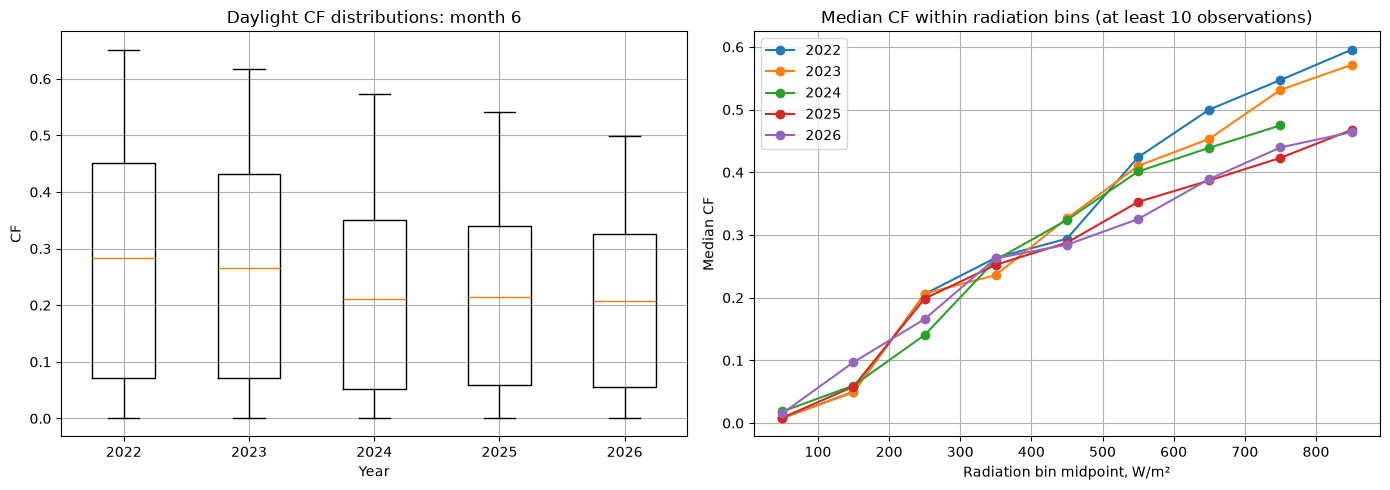

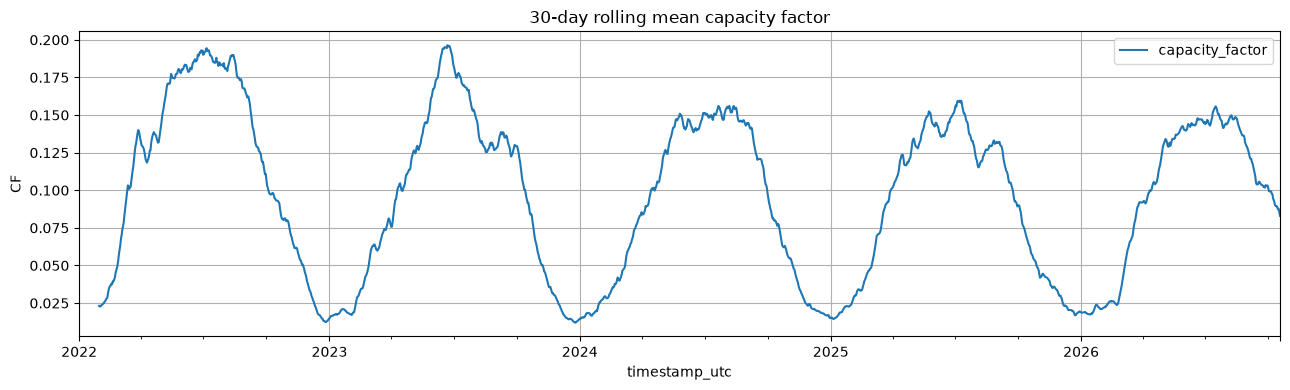

In [25]:
comparison = daylight.loc[daylight.month_utc.eq(COMPARISON_MONTH)].copy()
years = sorted(comparison.year_utc.unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot(
    [
        comparison.loc[comparison.year_utc.eq(year), "capacity_factor"].dropna()
        for year in years
    ],
    tick_labels=[str(year) for year in years],
    showfliers=False,
)
axes[0].set_title(f"Daylight CF distributions: month {COMPARISON_MONTH}")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CF")

comparison["radiation_bin"] = pd.cut(
    comparison.weather_shortwave_radiation,
    bins=list(range(0, 1201, 100)),
    include_lowest=True,
)
binned = comparison.groupby(
    ["year_utc", "radiation_bin"], observed=True
).capacity_factor.agg(["median", "count"])
for year in years:
    values = binned.loc[year]
    values = values.loc[values["count"].ge(10)]
    axes[1].plot(
        [interval.mid for interval in values.index],
        values["median"],
        marker="o",
        label=str(year),
    )
axes[1].set_title("Median CF within radiation bins (at least 10 observations)")
axes[1].set_xlabel("Radiation bin midpoint, W/m²")
axes[1].set_ylabel("Median CF")
axes[1].legend()
plt.tight_layout()
plt.show()

daily[["capacity_factor"]].rolling(30, min_periods=30).mean().plot(
    title="30-day rolling mean capacity factor"
)
plt.ylabel("CF")
plt.tight_layout()
plt.show()

Matching a month or radiation bin does not control every weather or fleet difference. Record suspicious periods and the evidence for any proposed preprocessing change before modifying data or training models.